# 05 — Rolling-origin evaluation + Hawkes-proxy features
Implements the top two items of the research report (`reports/Improving air raid alert forecasts.md`):

1. **Rolling-origin (walk-forward) evaluation** — 6 monthly test folds instead of a single test month
   ([fpp3 §5.10](https://otexts.com/fpp3/tscv.html), [Bergmeir & Benítez 2012](https://doi.org/10.1016/j.ins.2011.12.028)).
   Each fold: train 365 days → **embargo 60 min** → early-stopping block (30 days) → embargo → test month.
   The neighbour graph (lift) and the frontline/rear split are re-estimated **inside every fold on its train part only**.
   Metrics: mean per-oblast PR-AUC, **PR-AUC / prevalence (lift)** per oblast, **Brier skill score** vs climatology, log loss.
2. **Hawkes-proxy features (v3)** — exponentially decayed counts of past alert starts with half-lives 15 min / 1 h / 6 h / 24 h,
   for the oblast itself, border neighbours, macro-region and the whole country. These are the components of a
   self-exciting (Hawkes) intensity ([Mohler et al. 2011](https://doi.org/10.1198/jasa.2011.ap09546)) without fitting one.

Hyper-parameters are fixed in advance (same as notebook 04) — nothing is tuned on the test folds.

In [1]:
import json, sys, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from pathlib import Path
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss

sys.path.insert(0, str(Path.cwd()))
from src.data import load_clean, sub_grid
from src.features import (build_features_v3, build_targets, compute_lift, HORIZONS, STEP,
                          OWN, CAL, SPATIAL, WAVE, ADJ_F, SUB, DECAY, nbr_cols)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4)
DATA_DIR = Path("data")

state_all  = pd.read_parquet(DATA_DIR / "state_5min.parquet")
starts_all = pd.read_parquet(DATA_DIR / "starts_5min.parquet")
END = state_all.index[-1]

N_FOLDS, TEST_DAYS, ES_DAYS, TRAIN_DAYS = 6, 30, 30, 365
EMBARGO = pd.Timedelta("60min")                        # = longest horizon → no target overlap
TRAIN_EVERY = 2                                        # train rows every 10 min (memory), eval every 5 min

folds = []
for k in range(N_FOLDS):
    test_end   = (END - pd.Timedelta(days=TEST_DAYS * k)).floor("5min")
    test_start = test_end - pd.Timedelta(days=TEST_DAYS)
    es_start   = test_start - pd.Timedelta(days=ES_DAYS)
    train_start = es_start - pd.Timedelta(days=TRAIN_DAYS)
    folds.append(dict(fold=N_FOLDS - k, train_start=train_start, es_start=es_start,
                      test_start=test_start, test_end=test_end))
folds = pd.DataFrame(folds).sort_values("fold").reset_index(drop=True)

lo = folds.train_start.min() - pd.Timedelta(days=10)    # warm-up for 24h/7d look-backs and decays
state_all, starts_all = state_all.loc[lo:], starts_all.loc[lo:]
oblasts = list(state_all.columns)
raw = load_clean(DATA_DIR / "official_data_en.csv")
sub_all, full_all = sub_grid(raw, state_all.index, oblasts)
folds

,fold,train_start,es_start,test_start,test_end
0,1,2025-02-09 07:40:00+02:00,2026-02-09 07:40:00+02:00,2026-03-11 07:40:00+02:00,2026-04-10 08:40:00+03:00
1,2,2025-03-11 07:40:00+02:00,2026-03-11 07:40:00+02:00,2026-04-10 08:40:00+03:00,2026-05-10 08:40:00+03:00
2,3,2025-04-10 08:40:00+03:00,2026-04-10 08:40:00+03:00,2026-05-10 08:40:00+03:00,2026-06-09 08:40:00+03:00
3,4,2025-05-10 08:40:00+03:00,2026-05-10 08:40:00+03:00,2026-06-09 08:40:00+03:00,2026-07-09 08:40:00+03:00
4,5,2025-06-09 08:40:00+03:00,2026-06-09 08:40:00+03:00,2026-07-09 08:40:00+03:00,2026-08-08 08:40:00+03:00
5,6,2025-07-09 08:40:00+03:00,2026-07-09 08:40:00+03:00,2026-08-08 08:40:00+03:00,2026-09-07 08:40:00+03:00


In [2]:
FEATS = {
    "LightGBM-own": OWN + CAL,
    "LightGBM v2":  OWN + CAL + SPATIAL + nbr_cols() + WAVE + ADJ_F + SUB,
    "LightGBM v3 (+decay)": OWN + CAL + SPATIAL + nbr_cols() + WAVE + ADJ_F + SUB + DECAY,
}
PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=63, min_data_in_leaf=500,
              feature_fraction=0.7, bagging_fraction=0.7, bagging_freq=1, lambda_l2=5.0, verbose=-1, seed=0)

def recency_weight(X, ref, half_life_days=180):
    age = (ref - X.index.get_level_values("time")).total_seconds() / 86400
    return np.asarray(0.5 ** (age / half_life_days), dtype=float)

def climatology(Xtr, ytr, X):
    tab = ytr.groupby([Xtr.index.get_level_values("oblast"), (Xtr.index.get_level_values("time") + STEP).hour]).mean()
    key = pd.MultiIndex.from_arrays([X.index.get_level_values("oblast"), (X.index.get_level_values("time") + STEP).hour])
    return tab.reindex(key).values

## Run all folds

In [3]:
all_preds, fold_meta = [], []
for f in folds.itertuples():
    t0 = time.time()
    lift  = compute_lift(starts_all, f.es_start)                                # train-only graph
    front = state_all.loc[f.train_start:f.es_start].mean().pipe(lambda s: s[s > .25].index.tolist())
    idx = state_all.index
    T = {"train": idx[(idx >= f.train_start) & (idx < f.es_start - EMBARGO)][::TRAIN_EVERY],
         "es":    idx[(idx >= f.es_start) & (idx < f.test_start - EMBARGO)],
         "test":  idx[(idx >= f.test_start) & (idx < min(f.test_end, idx[-1]) - EMBARGO)]}
    D = {}
    for part, t in T.items():
        X = build_features_v3(state_all, starts_all, lift, t, sub_all, full_all).astype(np.float32)
        X["oblast"] = pd.Categorical(X.index.get_level_values("oblast"), categories=oblasts)
        D[part] = (X, build_targets(starts_all, t))
    Xtr, Ytr = D["train"]; Xes, Yes = D["es"]; Xte, Yte = D["test"]
    w = recency_weight(Xtr, f.es_start)
    for h in HORIZONS:
        P = pd.DataFrame({"y": Yte[f"y_{h}"].values,
                          "Climatology": climatology(Xtr, Ytr[f"y_{h}"], Xte)}, index=Xte.index)
        for name, feats in FEATS.items():
            dtr = lgb.Dataset(Xtr[feats + ["oblast"]], Ytr[f"y_{h}"], weight=w)
            des = lgb.Dataset(Xes[feats + ["oblast"]], Yes[f"y_{h}"], reference=dtr)
            m = lgb.train(PARAMS, dtr, 4000, valid_sets=[des], callbacks=[lgb.early_stopping(200, verbose=False)])
            P[name] = m.predict(Xte[feats + ["oblast"]])
            if f.fold == folds.fold.max() and h == "30min" and name.startswith("LightGBM v3"):
                last_model = m
        P["fold"], P["horizon"] = f.fold, h
        P["front"] = P.index.get_level_values("oblast").isin(front)
        all_preds.append(P)
    print(f"fold {f.fold}: test {f.test_start.date()} → {f.test_end.date()}  ({time.time()-t0:.0f}s)")
    del D, Xtr, Xes, Xte; gc.collect()

preds = pd.concat(all_preds)
preds.to_parquet(DATA_DIR / "preds_05_rolling.parquet")
MODELS = ["Climatology"] + list(FEATS)

fold 1: test 2026-03-11 → 2026-04-10  (289s)


fold 2: test 2026-04-10 → 2026-05-10  (269s)


fold 3: test 2026-05-10 → 2026-06-09  (371s)


fold 4: test 2026-06-09 → 2026-07-09  (274s)


fold 5: test 2026-07-09 → 2026-08-08  (264s)


fold 6: test 2026-08-08 → 2026-09-07  (334s)


## Metrics per fold
- **mean AP** — mean per-oblast PR-AUC (oblasts with ≥ 5 positives in the fold)
- **mean AP lift** — mean per-oblast PR-AUC ÷ prevalence (1 = random); comparable across oblasts with different base rates
- **BSS** — Brier skill score vs climatology (pooled), 1 − Brier/Brier_clim
- **log loss** (pooled)

In [4]:
def fold_metrics(P, cols_mask=None):
    if cols_mask is not None: P = P[cols_mask(P)]
    P = P.dropna(subset=MODELS + ["y"])
    out = {}
    bs_clim = brier_score_loss(P.y, P["Climatology"])
    for m in MODELS:
        ap, lift_ = [], []
        for o, g in P.groupby(level="oblast"):
            if g.y.sum() >= 5:
                a = average_precision_score(g.y, g[m]); ap.append(a); lift_.append(a / g.y.mean())
        out[m] = {"mean AP": np.mean(ap), "mean AP lift": np.mean(lift_),
                  "BSS": 1 - brier_score_loss(P.y, P[m].clip(0, 1)) / bs_clim,
                  "log loss": log_loss(P.y, P[m].clip(1e-6, 1 - 1e-6))}
    return pd.DataFrame(out).T

rows = []
for (fold, h), P in preds.groupby(["fold", "horizon"]):
    for grp, mask in {"all": None, "rear": lambda d: ~d.front, "frontline": lambda d: d.front}.items():
        r = fold_metrics(P, mask).rename_axis("model").reset_index()
        r["fold"], r["horizon"], r["group"] = fold, h, grp
        rows.append(r)
res = pd.concat(rows)
res.to_csv(DATA_DIR / "results_05_rolling.csv", index=False)

In [5]:
def summary(metric, group):
    t = res.query("group == @group").groupby(["model", "horizon"])[metric].agg(["mean", "std"])
    t = t["mean"].round(3).astype(str) + " ± " + t["std"].round(3).astype(str)
    return t.unstack("horizon").loc[MODELS, list(HORIZONS)]

for metric in ["mean AP", "mean AP lift", "BSS", "log loss"]:
    for grp in ["all", "rear"]:
        print(f"\n=== {metric} — {grp} — mean ± sd over {N_FOLDS} folds ===")
        print(summary(metric, grp))


=== mean AP — all — mean ± sd over 6 folds ===
horizon                       15min          30min          60min
model                                                            
Climatology           0.034 ± 0.005  0.069 ± 0.009   0.13 ± 0.017
LightGBM-own           0.11 ± 0.015  0.168 ± 0.022  0.232 ± 0.028
LightGBM v2           0.152 ± 0.018   0.222 ± 0.02  0.295 ± 0.026
LightGBM v3 (+decay)  0.153 ± 0.022  0.221 ± 0.021  0.291 ± 0.026

=== mean AP — rear — mean ± sd over 6 folds ===
horizon                       15min          30min          60min
model                                                            
Climatology           0.026 ± 0.005   0.052 ± 0.01    0.1 ± 0.019
LightGBM-own          0.041 ± 0.013  0.075 ± 0.024  0.129 ± 0.037
LightGBM v2           0.097 ± 0.023  0.147 ± 0.031   0.21 ± 0.037
LightGBM v3 (+decay)    0.1 ± 0.029  0.147 ± 0.031  0.207 ± 0.037

=== mean AP lift — all — mean ± sd over 6 folds ===
horizon                         15min           30min     

## Does v3 (+decay) beat v2? Paired comparison over folds

In [6]:
cmp = []
for h in HORIZONS:
    for grp in ["all", "rear", "frontline"]:
        t = res.query("horizon == @h and group == @grp").pivot(index="fold", columns="model", values="mean AP")
        for a, b in [("LightGBM v3 (+decay)", "LightGBM v2"), ("LightGBM v2", "LightGBM-own")]:
            d = t[a] - t[b]
            cmp.append({"horizon": h, "group": grp, "comparison": f"{a} − {b}",
                        "mean Δ AP": d.mean(), "min Δ": d.min(), "max Δ": d.max(),
                        "folds won": f"{(d > 0).sum()}/{len(d)}"})
pd.DataFrame(cmp).round(4)

,horizon,group,comparison,mean Δ AP,min Δ,max Δ,folds won
0,15min,all,LightGBM v3 (+decay) − LightGBM v2,0.0006,-0.0093,0.0074,3/6
1,15min,all,LightGBM v2 − LightGBM-own,0.0425,0.0299,0.0566,6/6
2,15min,rear,LightGBM v3 (+decay) − LightGBM v2,0.0028,-0.0120,0.0144,5/6
3,15min,rear,LightGBM v2 − LightGBM-own,0.0560,0.0375,0.0746,6/6
4,15min,frontline,LightGBM v3 (+decay) − LightGBM v2,-0.0038,-0.0125,0.0056,2/6
5,15min,frontline,LightGBM v2 − LightGBM-own,0.0120,0.0008,0.0279,6/6
6,30min,all,LightGBM v3 (+decay) − LightGBM v2,-0.0012,-0.0043,0.0019,1/6
7,30min,all,LightGBM v2 − LightGBM-own,0.0547,0.0319,0.0807,6/6
8,30min,rear,LightGBM v3 (+decay) − LightGBM v2,0.0001,-0.0055,0.0094,3/6
9,30min,rear,LightGBM v2 − LightGBM-own,0.0720,0.0415,0.0982,6/6


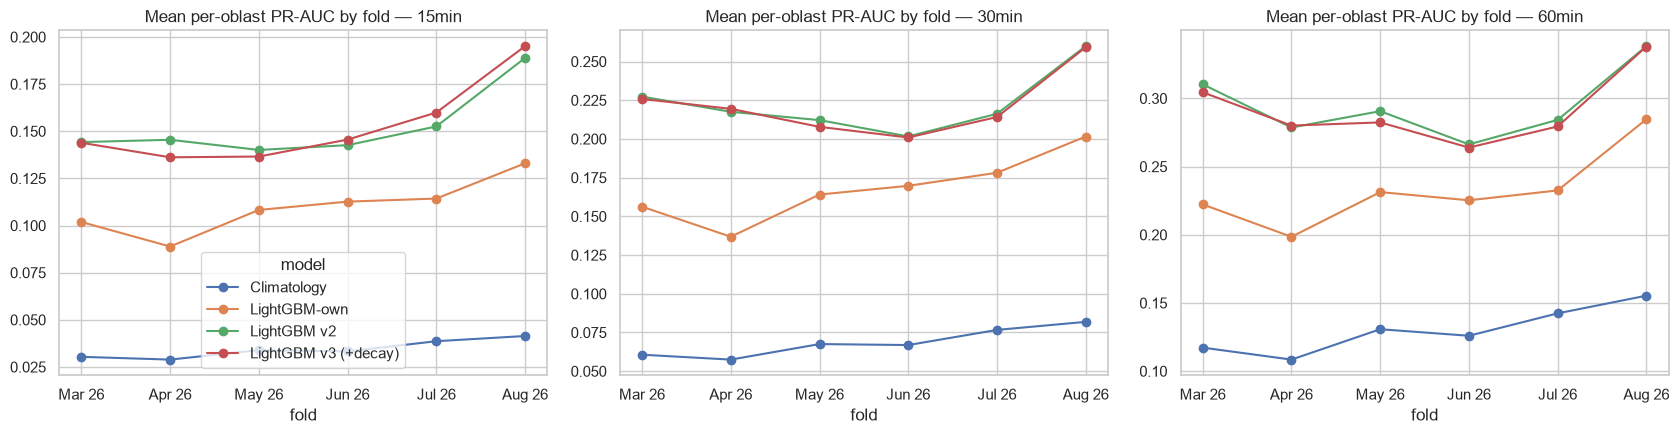

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), sharey=False)
for a, h in zip(ax, HORIZONS):
    t = res.query("horizon == @h and group == 'all'").pivot(index="fold", columns="model", values="mean AP")[MODELS]
    t.plot(marker="o", ax=a, legend=(h == "15min"), title=f"Mean per-oblast PR-AUC by fold — {h}")
    a.set_xticks(folds.fold); a.set_xticklabels([d.strftime("%b %y") for d in folds.test_start], rotation=0)
plt.tight_layout(); plt.show()

## Which decay features matter? (v3, h = 30 min, latest fold)

share of gain from decay features: 0.249


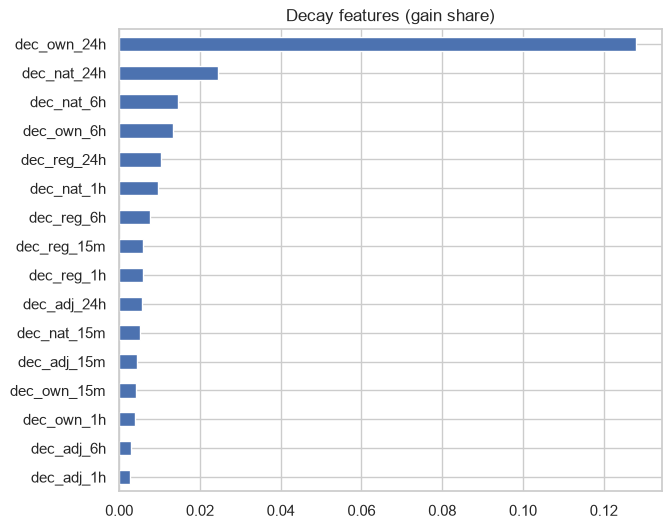

In [8]:
imp = pd.Series(last_model.feature_importance("gain"), index=last_model.feature_name())
imp = imp / imp.sum()
print("share of gain from decay features:", round(imp[[c for c in imp.index if c.startswith("dec_")]].sum(), 3))
imp[[c for c in imp.index if c.startswith("dec_")]].sort_values().plot.barh(figsize=(7, 6), title="Decay features (gain share)")
plt.show()

## Conclusions (fill in after running)
- Benchmark across 6 folds (mean ± sd): …
- v3 vs v2: …
- Stability over time / drift: …